--- GLOBAL METRICS (D = 1.0) ---
Total Egress Time (TET):       46.28 seconds
Peak Bottleneck Density:       5 agents in zone
Mean Agent Exit Time:          31.33 seconds
Std Dev of Exit Times:         9.00 seconds


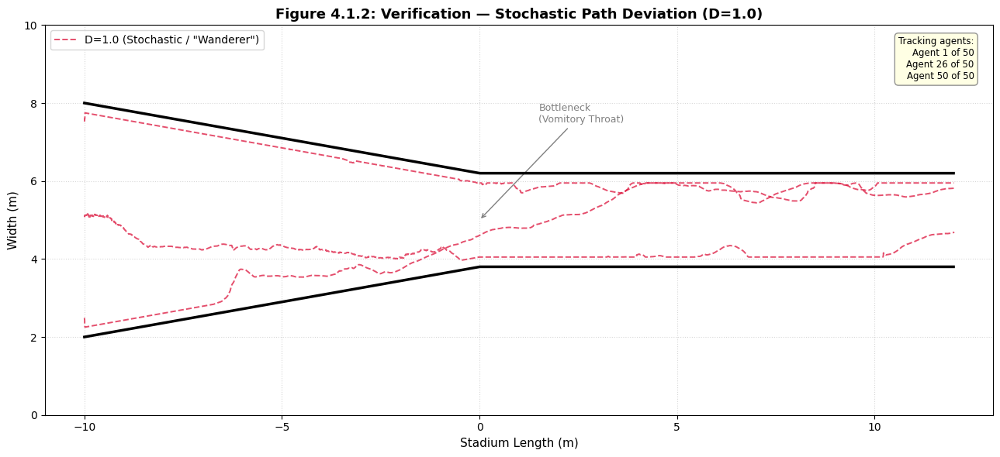

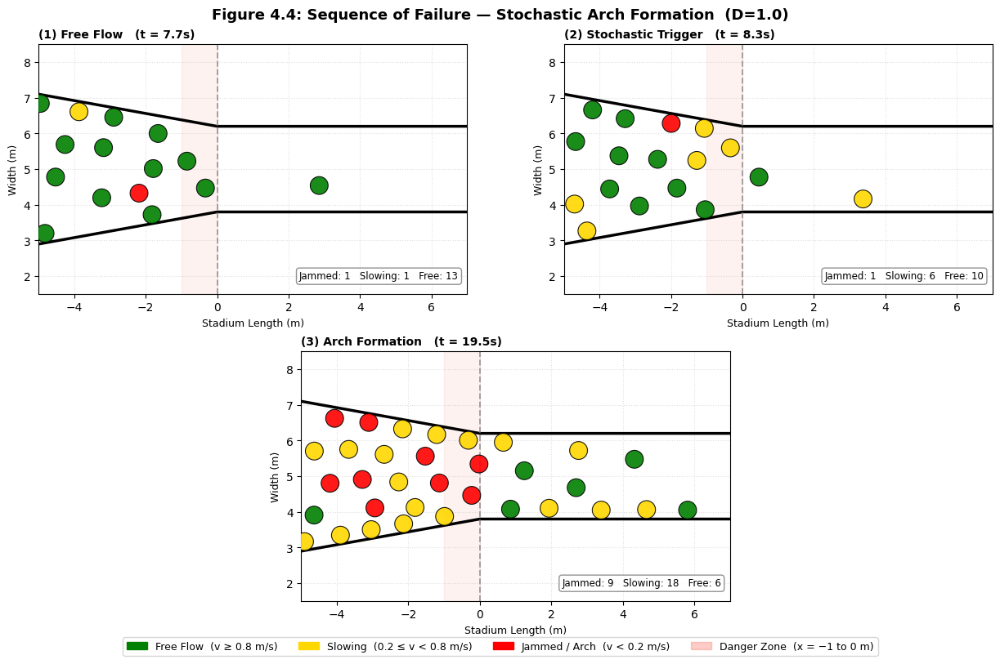

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib as mpl

# COMPONENT 1 - Simulation Constants & Parameters

dt = 0.02
n_agents = 50
m = 70.0
tau = 0.5
v0_desired = 1.34

# EXPERIMENTAL VARIABLES (Only change these for your results)
D_val = 1.0           # Scenario Noise  <-- SET TO 0.0 FOR ROBOTIC TEST, 1.0 FOR STOCHASTIC
vomitory_width = 2.4  # Bottleneck Width

# HEURISTIC CALIBRATION CONSTANTS (Fixed for all runs to ensure stability) [Section 4.2.2]
# Wall Physics
k_wall = 7500.0      # High stiffness for concrete boundaries
buffer_wall = 0.25     # Low buffer for hard walls
c_wall_damp = 1000.0  # Damping to prevent bouncing off walls

# Social Physics
k_soc = 5000.0        # Stiff social repulsion for "Granular" behavior
buffer_soc = 1.0      # Realistic human buffer zone
c_soc_damp = 750.0    # Social damping to facilitate clogging/freezing
lambda_aniso = 0.1    # People behind you have 90% less influence
agent_radius = 0.25

# Force and Velocity Caps
cap_drive = 1000.0    # Calibrated to allow social stalling
cap_bound = 5000.0    # High to prevent clipping
cap_soc = 3500.0      # Allows social force to win over intent
v_cap = 3.0

# Geometry Setup
x_spawn_line, x_funnel_start, x_bottleneck, exit_target_x = -10.0, -10.0, 0.0, 12.0
y_corridor_low = 5.0 - (vomitory_width / 2)
y_corridor_high = 5.0 + (vomitory_width / 2)
stadium_opening_width = 6.0
y_stadium_low, y_stadium_high = 2.0, 8.0
slope_top = (y_corridor_high - y_stadium_high) / (x_bottleneck - x_funnel_start)
slope_bot = (y_corridor_low - y_stadium_low) / (x_bottleneck - x_funnel_start)


# COMPONENT 2 - Initialising Agents [Section 3.3.2]

# "Pulse" spawning to trigger immediate clog
entry_delay = 0.05
entry_times = np.arange(n_agents) * entry_delay

# Agent Heterogeneity (Noise and Mass slightly varied to break symmetry)
# D=0 FIX: np.maximum(0, ...) clamps the per-agent D values at zero,
# preventing a negative value under the sqrt in Step 2 when D_val = 0.0.
# The uniform jitter is kept so mass/geometry still breaks symmetry at D=0.
D_agents = np.maximum(0, np.full(n_agents, D_val) + np.random.uniform(-0.05, 0.05, n_agents))
# Small mass variation is common in engineering to break mathematical deadlocks
m_agents = np.full(n_agents, m) + np.random.uniform(-2, 2, n_agents)

# Start positions: Vertical spread across the ENTIRE WIDE opening at x=-10
pos = np.zeros((n_agents, 2))
pos[:, 0] = x_spawn_line
pos[:, 1] = np.linspace(y_stadium_low + 0.5, y_stadium_high - 0.5, n_agents)

vel = np.zeros((n_agents, 2))
exited_mask = np.zeros(n_agents, dtype=bool)

# The "Brain" Lists - Initializing empty lists to store time-series data
history_pos = []      # Stores [x, y] coordinates for every agent
history_vel = []      # Stores [vx, vy] vectors (needed for speed-based coloring)
history_density = []  # Stores a single integer (count of agents in Danger Zone)

# Function to calculate wall height based on current x-coordinate
def get_wall_heights(x):
    """Calculates y_low and y_high at a given x for funnel geometry."""
    y_high = np.piecewise(x, [x < x_bottleneck, x >= x_bottleneck],
                          [lambda x: y_stadium_high + slope_top * (x - x_funnel_start),
                           y_corridor_high])
    y_low = np.piecewise(x, [x < x_bottleneck, x >= x_bottleneck],
                         [lambda x: y_stadium_low + slope_bot * (x - x_funnel_start),
                          y_corridor_low])
    return y_low, y_high


# COMPONENT 3 - Simulation Loop

for step in range(15000):
    t = step * dt
    active_mask = t >= entry_times
    exited_mask[pos[:, 0] >= exit_target_x] = True
    in_sim_mask = active_mask & ~exited_mask

    if not np.any(in_sim_mask):
        if np.all(exited_mask): break
        continue

    # Step 1 - Force Summation (F_det)

    # 1a - F_drive: Zone-Based Intent [Section 3.3.2]
    f_drive = np.zeros_like(pos)
    e_i = np.zeros_like(pos)
    funnel_zone = (pos[:, 0] < x_bottleneck) & in_sim_mask
    corridor_zone = (pos[:, 0] >= x_bottleneck) & in_sim_mask

    # Target center of bottleneck
    target_funnel = np.array([x_bottleneck, 5.0])
    diff_funnel = target_funnel - pos[funnel_zone]
    e_i[funnel_zone] = diff_funnel / (np.linalg.norm(diff_funnel, axis=1, keepdims=True) + 1e-6)

    # Target line at x=12
    e_i[corridor_zone] = np.array([1.0, 0.0])
    f_drive[in_sim_mask] = m * (v0_desired * e_i[in_sim_mask] - vel[in_sim_mask]) / tau

    # 1b - F_bound: Corrected Non-Sucking Logic [Section 3.3.2]
    f_bound = np.zeros_like(pos)
    for i in np.where(in_sim_mask)[0]:
        xi, yi = pos[i, 0], pos[i, 1]

        # Determine normals based on geometry (Funnel vs Corridor)
        if xi < x_bottleneck:
            norm_top = np.array([-slope_top, -1.0]) / np.sqrt(slope_top**2 + 1)
            norm_bot = np.array([-slope_bot, 1.0]) / np.sqrt(slope_bot**2 + 1)
        else:
            norm_top, norm_bot = np.array([0.0, -1.0]), np.array([0.0, 1.0])

        y_low_w, y_high_w = get_wall_heights(xi)
        dist_top = y_high_w - yi
        dist_bot = yi - y_low_w

        # TOP WALL: Repulsion - Damping
        overlap_top = np.maximum(0, buffer_wall - dist_top)
        if overlap_top > 0:
            v_norm_top = np.dot(vel[i], norm_top)
            # max(0, ...) ensures the wall NEVER pulls the agent in
            f_mag_top = np.maximum(0, (k_wall * overlap_top) - (c_wall_damp * v_norm_top))
            f_bound[i] += f_mag_top * norm_top

        # BOTTOM WALL: Repulsion - Damping
        overlap_bot = np.maximum(0, buffer_wall - dist_bot)
        if overlap_bot > 0:
            v_norm_bot = np.dot(vel[i], norm_bot)
            f_mag_bot = np.maximum(0, (k_wall * overlap_bot) - (c_wall_damp * v_norm_bot))
            f_bound[i] += f_mag_bot * norm_bot

    # 1c - F_soc: Directional Weighting (Anisotropy) [Section 3.3.2]
    f_soc = np.zeros_like(pos)
    active_idx = np.where(in_sim_mask)[0]

    for i in active_idx:
        others = [j for j in active_idx if j != i]
        if not others: continue

        diff = pos[i] - pos[others]  # Vector from other to me
        dist = np.linalg.norm(diff, axis=1, keepdims=True)
        overlap = np.maximum(0, buffer_soc - dist)
        n_ij = diff / (dist + 1e-6)  # Unit vector

        # ANISOTROPY: Weight neighbors based on if they are in front
        # We look at the dot product between my velocity and the vector to the neighbor
        # A person in front will have a negative dot product with n_ij
        cos_phi = np.sum(-n_ij * (vel[i] / (np.linalg.norm(vel[i]) + 1e-6)), axis=1, keepdims=True)
        w_ij = np.where(cos_phi >= 0, 1.0, lambda_aniso)

        v_rel = vel[i] - vel[others]
        f_rep = k_soc * overlap * n_ij
        f_damp = -c_soc_damp * (overlap > 0) * v_rel

        # Apply the directional weight
        f_soc[i] = np.sum(w_ij * (f_rep + f_damp), axis=0)

    # 1d - Hierarchical Capping [Section 4.2.2]
    def cap_vec(f, cap):
        mag = np.linalg.norm(f, axis=1, keepdims=True)
        return np.where(mag > cap, f * (cap / (mag + 1e-9)), f)

    f_drive = cap_vec(f_drive, cap_drive)
    f_bound = cap_vec(f_bound, cap_bound)
    f_soc = cap_vec(f_soc, cap_soc)

    # Step 2 - Langevin Noise (xi)
    # D=0 FIX: sqrt(2 * D_agents) is safe because D_agents was clamped at 0 in Component 2.
    # When D_val=0, D_agents=0 everywhere, so noise=0 exactly -> pure deterministic run.
    noise = np.zeros_like(pos)
    noise[in_sim_mask] = np.sqrt(2 * D_agents[in_sim_mask, np.newaxis]) * np.random.normal(0, 1, (np.sum(in_sim_mask), 2))

    # Step 3 - Velocity Update (EM)
    vel[in_sim_mask] += ((f_drive + f_bound + f_soc)[in_sim_mask] / m) * dt + noise[in_sim_mask] * np.sqrt(dt)
    vel[in_sim_mask, 0] = np.maximum(0, vel[in_sim_mask, 0])  # Velocity cannot be negative (no moving back to stadium)
    v_mag = np.linalg.norm(vel, axis=1, keepdims=True)         # Cap total speed to biological limits
    vel = np.where(v_mag > v_cap, vel * (v_cap / (v_mag + 1e-9)), vel)

    # Step 4 - Position Update
    pos[in_sim_mask] += vel[in_sim_mask] * dt

    # THE CLAMP: Force agents to stay inside the funnel/corridor
    y_low, y_high = get_wall_heights(pos[:, 0])
    pos[:, 1] = np.clip(pos[:, 1], y_low + agent_radius, y_high - agent_radius)

    vel[exited_mask] = 0

    # Step 5 - Logging
    history_pos.append(pos.copy())
    history_vel.append(vel.copy())
    history_density.append(np.sum((pos[:, 0] >= -1.0) & (pos[:, 0] <= 0.0) & in_sim_mask))


# COMPONENT 4 - Final Metric Extraction [Section 3.3.3]

# 4.1 Convert Lists to Arrays
history_pos = np.array(history_pos)
history_vel = np.array(history_vel)
history_density = np.array(history_density)

# 4.2 Total Egress Time (TET)
# Find the exact frame when the LAST agent crossed x=12
individual_exit_frames = []
for i in range(n_agents):
    exited = np.where(history_pos[:, i, 0] >= exit_target_x)[0]
    if len(exited) > 0:
        individual_exit_frames.append(exited[0])
    else:
        individual_exit_frames.append(len(history_pos) - 1)  # Timed out

final_egress_frame = max(individual_exit_frames)
total_egress_time = final_egress_frame * dt

# 4.3 Individual Exit Times (for waterfall / exit-rate analysis if needed)
individual_exit_times = [f * dt for f in individual_exit_frames]

print(f"--- GLOBAL METRICS (D = {D_val}) ---")
print(f"Total Egress Time (TET):       {total_egress_time:.2f} seconds")
print(f"Peak Bottleneck Density:       {np.max(history_density):.0f} agents in zone")
print(f"Mean Agent Exit Time:          {np.mean(individual_exit_times):.2f} seconds")
print(f"Std Dev of Exit Times:         {np.std(individual_exit_times):.2f} seconds")


# COMPONENT 5 - Visualisation [Section 3.3.3]

# 5.1: Section 4.1 Verification Overlay (D=0 Robotic vs D=1 Stochastic)

fig_41, ax_41 = plt.subplots(figsize=(13, 6))

# Draw walls
walls_x = np.linspace(-10, 12, 500)
y_low_wall, y_high_wall = get_wall_heights(walls_x)
ax_41.plot(walls_x, y_high_wall, color='black', linewidth=2.5, zorder=5)
ax_41.plot(walls_x, y_low_wall, color='black', linewidth=2.5, zorder=5)

# Agent selection: show 3 representative agents (early, middle, late spawn)
selected_agents = [0, n_agents // 2, n_agents - 1]

# Plot current run trajectories
if D_val == 0.0:
    # D=0: solid blue lines -- the "Robotic" deterministic paths
    for i in selected_agents:
        mask = history_pos[:, i, 0] > -10.0
        ax_41.plot(history_pos[mask, i, 0], history_pos[mask, i, 1],
                   color='royalblue', linewidth=1.8, alpha=0.9,
                   label='D=0 (Deterministic / "Robotic")' if i == selected_agents[0] else "_nolegend_")
    ax_41.set_title(f'Figure 4.1.1: Verification — Deterministic Baseline (D=0)', fontsize=13, fontweight='bold')
else:
    # D>0: dashed red lines -- the "Wanderer" stochastic paths
    for i in selected_agents:
        mask = history_pos[:, i, 0] > -10.0
        ax_41.plot(history_pos[mask, i, 0], history_pos[mask, i, 1],
                   color='crimson', linewidth=1.4, alpha=0.75, linestyle='--',
                   label=f'D={D_val} (Stochastic / "Wanderer")' if i == selected_agents[0] else "_nolegend_")
    ax_41.set_title(f'Figure 4.1.2: Verification — Stochastic Path Deviation (D={D_val})', fontsize=13, fontweight='bold')

ax_41.set_xlabel('Stadium Length (m)', fontsize=11)
ax_41.set_ylabel('Width (m)', fontsize=11)
ax_41.set_xlim(-11, 13)
ax_41.set_ylim(0, 10)
ax_41.legend(fontsize=10, loc='upper left')
ax_41.grid(True, linestyle=':', alpha=0.5)
ax_41.annotate('Bottleneck\n(Vomitory Throat)', xy=(0, 5), xytext=(1.5, 7.5),
               arrowprops=dict(arrowstyle='->', color='gray'), fontsize=9, color='gray')
# Inside the figure, top-right info box
agent_label = '\n'.join([f'Agent {i+1} of {n_agents}' for i in selected_agents])
info_text = f'Tracking agents:\n{agent_label}'
ax_41.text(0.98, 0.97, info_text,
           transform=ax_41.transAxes,
           fontsize=8.5,
           verticalalignment='top',
           horizontalalignment='right',
           bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow', alpha=0.85, edgecolor='gray'))
plt.tight_layout()
plt.show()

# 5.2: Figure 4.4 — Sequence of Failure (2+1 Layout)
# Frames 1 and 2 side by side on top, Frame 3 centred below as the hero frame

frame_A = len(history_pos) // 6

frame_B = frame_A
for f in range(frame_A, len(history_pos)):
    near_bottleneck = (history_pos[f, :, 0] > -2.0) & (history_pos[f, :, 0] < 1.0)
    speeds_at_throat = np.linalg.norm(history_vel[f], axis=1)
    if np.any((speeds_at_throat < 0.2) & near_bottleneck):
        frame_B = f
        break

red_counts = []
for f in range(frame_B, len(history_pos)):
    near_bottleneck = (history_pos[f, :, 0] > -2.0) & (history_pos[f, :, 0] < 1.0)
    speeds_at_throat = np.linalg.norm(history_vel[f], axis=1)
    red_counts.append(np.sum((speeds_at_throat < 0.2) & near_bottleneck))
frame_C = frame_B + int(np.argmax(red_counts))

frames_seq   = [frame_A, frame_B, frame_C]
frame_labels = ['(1) Free Flow', '(2) Stochastic Trigger', '(3) Arch Formation']

def draw_frame(ax, frame, label):
    # Walls
    walls_x_seq = np.linspace(-5, 7, 400)
    y_low_seq, y_high_seq = get_wall_heights(walls_x_seq)
    ax.plot(walls_x_seq, y_high_seq, color='black', linewidth=2.5)
    ax.plot(walls_x_seq, y_low_seq,  color='black', linewidth=2.5)

    # Agents
    for i in range(n_agents):
        xi = history_pos[frame, i, 0]
        yi = history_pos[frame, i, 1]
        if xi < -5.0 or xi > 7.0:
            continue
        v_mag = np.linalg.norm(history_vel[frame, i])
        if xi >= exit_target_x:
            color = 'black'
        elif v_mag < 0.2:
            color = 'red'
        elif v_mag < 0.8:
            color = 'gold'
        else:
            color = 'green'
        circle = plt.Circle((xi, yi), agent_radius,
                             facecolor=color, edgecolor='black',
                             linewidth=0.8, alpha=0.9, zorder=3)
        ax.add_patch(circle)

    # Bottleneck line + danger zone
    ax.axvline(x=0, color='gray', linestyle='--', linewidth=1.4, alpha=0.7)
    ax.axvspan(-1, 0, color='salmon', alpha=0.10)

    # Agent count box
    in_view      = (history_pos[frame, :, 0] >= -5.0) & (history_pos[frame, :, 0] <= 7.0)
    speeds_view  = np.linalg.norm(history_vel[frame], axis=1)
    n_red        = np.sum((speeds_view < 0.2)  & in_view)
    n_yellow     = np.sum((speeds_view < 0.8)  & (speeds_view >= 0.2) & in_view)
    n_green      = np.sum((speeds_view >= 0.8) & in_view)
    stats_text   = f'Jammed: {n_red}   Slowing: {n_yellow}   Free: {n_green}'
    ax.text(0.98, 0.05, stats_text, transform=ax.transAxes,
            fontsize=8.5, ha='right', va='bottom',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                      edgecolor='gray', alpha=0.85))

    ax.set_xlim(-5, 7)
    ax.set_ylim(1.5, 8.5)
    ax.set_aspect('equal')
    ax.set_title(f'{label}   (t = {frame * dt:.1f}s)',
                 fontsize=10, fontweight='bold', loc='left')
    ax.set_xlabel('Stadium Length (m)', fontsize=9)
    ax.set_ylabel('Width (m)', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.4)

# Build the 2+1 layout
fig_52 = plt.figure(figsize=(13, 8))
fig_52.suptitle(f'Figure 4.4: Sequence of Failure — Stochastic Arch Formation  (D={D_val})',
                fontsize=13, fontweight='bold')

ax1 = fig_52.add_subplot(2, 2, 1)   # Top-left
ax2 = fig_52.add_subplot(2, 2, 2)   # Top-right
ax3 = fig_52.add_subplot(2, 1, 2)   # Full-width bottom (hero frame)

draw_frame(ax1, frames_seq[0], frame_labels[0])
draw_frame(ax2, frames_seq[1], frame_labels[1])
draw_frame(ax3, frames_seq[2], frame_labels[2])

# Shared legend
legend_patches = [
    mpatches.Patch(color='green',  label='Free Flow  (v ≥ 0.8 m/s)'),
    mpatches.Patch(color='gold',   label='Slowing  (0.2 ≤ v < 0.8 m/s)'),
    mpatches.Patch(color='red',    label='Jammed / Arch  (v < 0.2 m/s)'),
    mpatches.Patch(color='salmon', alpha=0.4, label='Danger Zone  (x = −1 to 0 m)'),
]
fig_52.legend(handles=legend_patches, loc='lower center', ncol=4,
              fontsize=9, bbox_to_anchor=(0.5, -0.02), frameon=True)

plt.tight_layout()
plt.show()

In [ ]:
# Figure 5.3: Speed-Based Animation (Section 4.4 Visual Proof)
# Red = Stopped/Jammed (v < 0.2 m/s) | Yellow = Slowing (v < 0.8 m/s) | Green = Free Flow
# Use this to grab the "Red Arch" screenshot for Section 4.4

fig_anim, ax_anim = plt.subplots(figsize=(13, 6))

# Draw the Funnel Boundaries (Static in the animation)
walls_x_ani = np.linspace(-12, exit_target_x + 2, 500)
walls_y_low_ani, walls_y_high_ani = get_wall_heights(walls_x_ani)
ax_anim.plot(walls_x_ani, walls_y_high_ani, color='black', linewidth=3)
ax_anim.plot(walls_x_ani, walls_y_low_ani, color='black', linewidth=3)

# Initialize agent circles (radius = agent_radius)
circles = [plt.Circle((0, 0), agent_radius, ec='black', alpha=0.85) for _ in range(n_agents)]
for circle in circles:
    ax_anim.add_patch(circle)

# Legend patches for the colour key
legend_patches = [
    mpatches.Patch(color='green',  label='Free Flow  (v ≥ 0.8 m/s)'),
    mpatches.Patch(color='yellow', label='Slowing      (0.2 ≤ v < 0.8 m/s)'),
    mpatches.Patch(color='red',    label='Jammed/Arch (v < 0.2 m/s)'),
    mpatches.Patch(color='black',  label='Inactive / Exited'),
]
ax_anim.legend(handles=legend_patches, loc='upper right', fontsize=8)

# Time label
time_text = ax_anim.text(0.02, 0.95, '', transform=ax_anim.transAxes, fontsize=10,
                         verticalalignment='top', color='white',
                         bbox=dict(boxstyle='round', facecolor='black', alpha=0.6))

# Map Formatting
ax_anim.set_aspect('equal')
ax_anim.set_xlim(-12, 14)
ax_anim.set_ylim(0, 10)
ax_anim.set_title(f'Active-Langevin: Speed-Based Monitoring — D={D_val}  (Red = Clogged)', fontsize=12, fontweight='bold')
ax_anim.set_xlabel('Stadium Length (m)')
ax_anim.set_ylabel('Width (m)')

def update(frame):
    """Updates position and colour based on location AND velocity."""
    time_text.set_text(f't = {frame * 10 * dt:.1f} s')  # 10 = downsample factor
    for i in range(n_agents):
        # 1. Update Position [history_pos slicing i, [x,y]]
        circles[i].center = history_pos[frame, i, 0], history_pos[frame, i, 1]

        xi = history_pos[frame, i, 0]

        # 2. Dynamic Coloring Logic
        # Agents are BLACK before they spawn and after they finish the vomitory

        # Condition A: Are they approaching or have they finished?
        if xi <= -10.0 or xi >= 12.0:
            circles[i].set_facecolor('black')  # "Inactive" or Finished

        # Condition B: Else, they are in the critical vomitory zone
        else:
            # 3. Calculate Speed Magnitude (inside the critical zone ONLY)
            v_mag = np.linalg.norm(history_vel[frame, i])

            # Speed thresholds for behavioral analysis [Section 4.4 Visual Proof]
            if v_mag < 0.2:
                circles[i].set_facecolor('red')     # Stopped / Physically Jammed (Arch)
            elif v_mag < 0.8:
                circles[i].set_facecolor('yellow')  # Slowing / Interaction dominant (Clog)
            else:
                circles[i].set_facecolor('green')   # Free Flow / Drive dominant

    return circles

# Create animation (Downsampled for efficiency)
frames_to_show = range(0, len(history_pos), 10)
ani = FuncAnimation(fig_anim, update, frames=frames_to_show, interval=100, blit=True)

plt.close()
HTML(ani.to_jshtml())

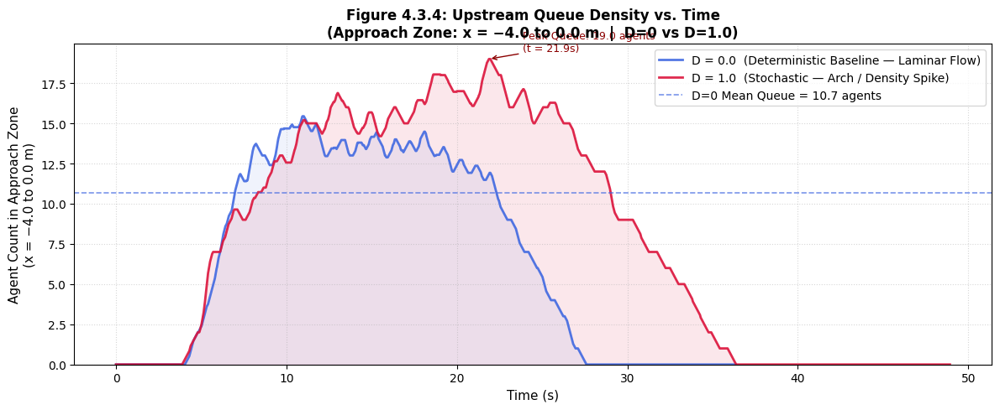

--- APPROACH ZONE STATS ---
D=0   mean queue length (active frames): 10.66 agents
D=1.0 peak queue length:             19.00 agents


In [ ]:
# 5.4: Figure 4.3 — Danger Zone Occupancy vs. Time (D=0 vs D=0.5 Comparison)
# WIDER ZONE VERSION: x = -4.0 to 0.0 (4m upstream approach)
# Captures the upstream QUEUE that forms during arch, not just the throat itself.
#
# HOW TO USE:
# Run 1: Set D_val = 0.0, run Components 1-4, then run:
#             history_density_D0 = history_density.copy()
#             history_pos_D0     = history_pos.copy()
# Run 2: Set D_val = 0.5, run Components 1-4, then run this full cell.

# Recompute density over wider 4m approach zone from raw position history
density_D0_wide  = np.sum((history_pos_D0[:, :, 0] >= -4.0) &
                           (history_pos_D0[:, :, 0] <=  0.0), axis=1)
density_cur_wide = np.sum((history_pos[:, :, 0]    >= -4.0) &
                           (history_pos[:, :, 0]    <=  0.0), axis=1)

time_axis_D0  = np.arange(len(density_D0_wide))  * dt
time_axis_cur = np.arange(len(density_cur_wide)) * dt

# Smooth both lines with a rolling average to reduce jaggedness
# Window of 25 frames = 0.5s — keeps the shape but removes single-frame spikes
def rolling_mean(arr, window=25):
    return np.convolve(arr, np.ones(window)/window, mode='same')

density_D0_smooth  = rolling_mean(density_D0_wide)
density_cur_smooth = rolling_mean(density_cur_wide)

# Plot
fig_55, ax_55 = plt.subplots(figsize=(12, 5))

ax_55.plot(time_axis_D0,  density_D0_smooth,
           color='royalblue', linewidth=2.0, alpha=0.9,
           label='D = 0.0  (Deterministic Baseline — Laminar Flow)')

ax_55.plot(time_axis_cur, density_cur_smooth,
           color='crimson', linewidth=2.0, alpha=0.9,
           label=f'D = {D_val}  (Stochastic — Arch / Density Spike)')

ax_55.fill_between(time_axis_cur, density_cur_smooth,
                   color='crimson', alpha=0.10)
ax_55.fill_between(time_axis_D0, density_D0_smooth,
                   color='royalblue', alpha=0.08)

# Annotate the stochastic peak
peak_val  = np.max(density_cur_smooth)
peak_time = time_axis_cur[np.argmax(density_cur_smooth)]
ax_55.annotate(f'Peak Queue: {peak_val:.1f} agents\n(t = {peak_time:.1f}s)',
               xy=(peak_time, peak_val),
               xytext=(peak_time + 2, peak_val + 0.5),
               arrowprops=dict(arrowstyle='->', color='darkred'),
               fontsize=9, color='darkred')

# D=0 mean reference line (only over active frames where agents are present)
active_D0  = density_D0_smooth[density_D0_smooth > 0.5]
mean_D0    = np.mean(active_D0) if len(active_D0) > 0 else 0
ax_55.axhline(y=mean_D0, color='royalblue', linestyle='--', linewidth=1.2, alpha=0.7,
              label=f'D=0 Mean Queue = {mean_D0:.1f} agents')

ax_55.set_title(f'Figure 4.3.4: Upstream Queue Density vs. Time\n'
                f'(Approach Zone: x = −4.0 to 0.0 m  |  D=0 vs D={D_val})',
                fontsize=12, fontweight='bold')
ax_55.set_xlabel('Time (s)', fontsize=11)
ax_55.set_ylabel('Agent Count in Approach Zone\n(x = −4.0 to 0.0 m)', fontsize=11)
ax_55.legend(fontsize=10)
ax_55.grid(True, linestyle=':', alpha=0.5)
ax_55.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

# Values to fill into 4.4.4 draft
print(f" APPROACH ZONE STATS ")
print(f"D=0   mean queue length (active frames): {mean_D0:.2f} agents")
print(f"D={D_val} peak queue length:             {peak_val:.2f} agents")

In [36]:
history_density_D0 = history_density.copy()
history_pos_D0     = history_pos.copy()